In [2]:
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"

# Model stuff
import tensorflow as tf
from tensorflow import keras
from keras.layers import Input, Conv2D
from keras.models import Model
from keras.utils import normalize
import segmentation_models as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler


import model_utility_rpjb
import preprocess_filter
import spoketools
import augment_trainingset

#path sorting
import glob
from pathlib import Path
import re

#math
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd

Segmentation Models: using `tf.keras` framework.


In [1]:
!pip install segmentation_models
!pip install albumentations==1.3.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 11.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.5/123.5 kB 16.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 27.6 MB/s eta 0:00:0000:0100:01


In [6]:
file_pattern = re.compile(r'.*?(\d+).*?')
def get_order(file):
    match = file_pattern.match(Path(file).name)
    if not match:
        return math.inf
    return int(match.groups()[0])


scaler = MinMaxScaler()
training_path_images = "../datasets/s3_compare"
X = []
for rpjb_filepath in sorted(glob.glob(training_path_images+"/*.rpjb"), key=get_order):
    pixel_values = preprocess_filter.apply_filters(rpjb_filepath, filter_imgs = False)
    pixel_values = scaler.fit_transform(pixel_values)
    X.append(pixel_values)


training_path_masks = "../datasets/c_masks"
Y = []
for mask_path in sorted(glob.glob(training_path_masks+"/*.npy"), key=get_order):
    mask = np.load(mask_path)
    mask = np.flipud(mask)
    mask[mask != 0] = 1
    Y.append(mask)

for aug in X:
    print(np.min(X))
    print(np.mean(X))
    print(np.max(X))
    print("********************************")

# if True:
#     X, Y = augment_trainingset.augment_semantic_set(X, Y, aug_num = 5)
#     print(len(X), len(Y))


[ 99666.66666667  99733.33333333  99800.          99866.66666667
  99933.33333333 100000.         100066.66666667 100133.33333333
 100200.         100266.66666667 100333.33333333 100400.
 100466.66666667 100533.33333333 100600.         100666.66666667
 100733.33333333 100800.         100866.66666667 100933.33333333
 101000.         101066.66666667 101133.33333333 101200.
 101266.66666667 101333.33333333 101400.         101466.66666667
 101533.33333333 101600.         101666.66666667 101733.33333333
 101800.         101866.66666667 101933.33333333 102000.
 102066.66666667 102133.33333333 102200.         102266.66666667
 102333.33333333 102400.         102466.66666667 102533.33333333
 102600.         102666.66666667 102733.33333333 102800.
 102866.66666667 102933.33333333 103000.         103066.66666667
 103133.33333333 103200.         103266.66666667 103333.33333333
 103400.         103466.66666667 103533.33333333 103600.
 103666.66666667 103733.33333333 103800.         103866.66666667


In [11]:
print(np.max(X[0]))
print(np.min(X[0]))

1.0000000000000009
0.0


In [8]:
for augmentation in X:
    print(np.mean(augmentation))

0.43646574630198826
0.48165390293049043
0.5392994262952037
0.5375085993621709
0.5339981225157207
0.4414419673073345
0.5229325129333575
0.5568417098050494
0.5611706864989735
0.5620027558379342
0.5361837542438972
0.5324281274484585
0.440306579458514
0.43639840871614227
0.4305122484285951


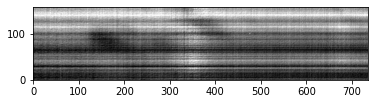

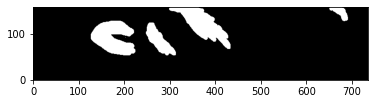

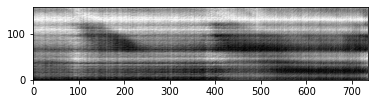

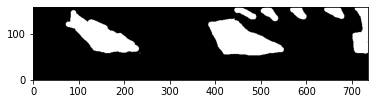

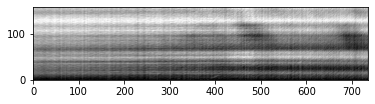

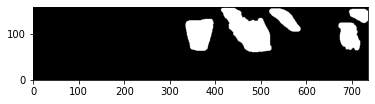

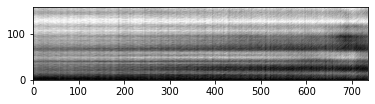

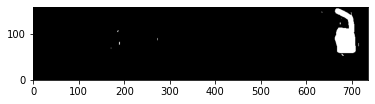

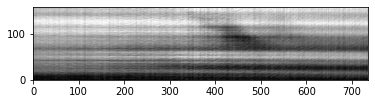

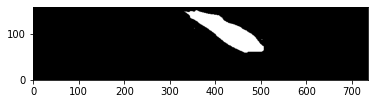

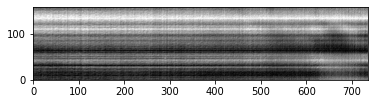

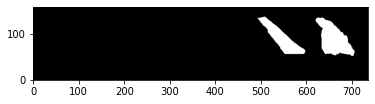

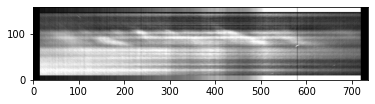

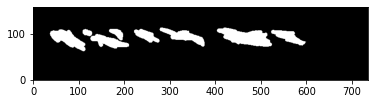

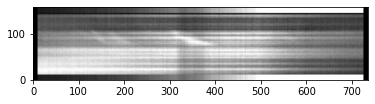

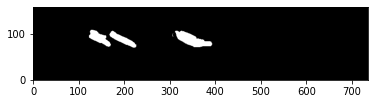

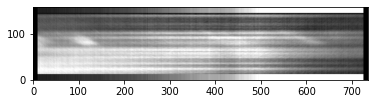

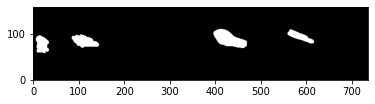

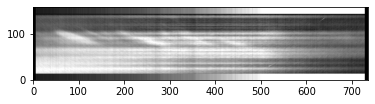

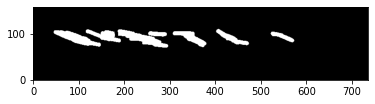

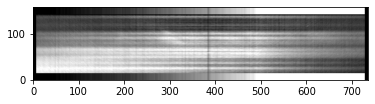

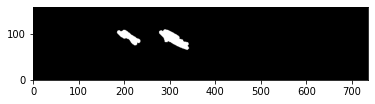

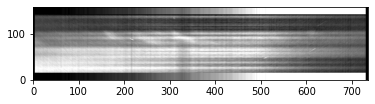

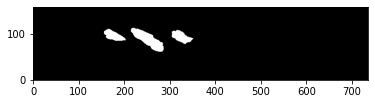

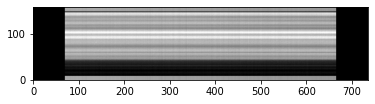

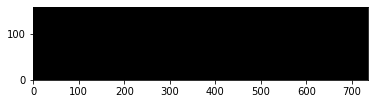

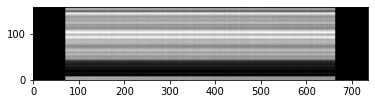

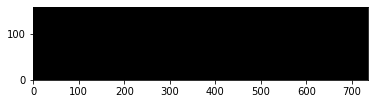

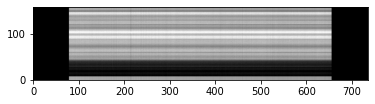

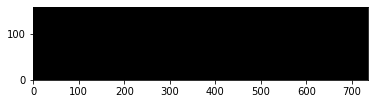

In [7]:
for image, mask in zip(X, Y):
    plt.imshow(image, cmap='gray', origin = 'lower')
    plt.show()
    plt.imshow(mask, cmap='gray', origin = 'lower')
    plt.show()